In [69]:
import json
import os
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import NYTimes_main as NYT
import prettytable as pt
import requests as rq

print(json.dumps(NYT.data["results"][0], indent=4))


{
    "uri": "nyt://article/3642a8f2-8adf-5fb3-a5a4-3ddf1f286b33",
    "url": "https://www.nytimes.com/2026/11/01/us/politics/el-sayed-stevens-meltdown-michigan-democrats.html",
    "id": 100000011253266,
    "asset_id": 100000011253266,
    "source": "New York Times",
    "published_date": "2026-11-01",
    "updated": "2026-11-02 20:41:45",
    "section": "U.S.",
    "subsection": "Politics",
    "nytdsection": "u.s.",
    "adx_keywords": "Midterm Elections (2026);Elections, Senate;United States Politics and Government;El-Sayed, Abdul;Stevens, Haley;Rogers, Michael J (1963- );Democratic Party;Republican Party;Israel;Michigan",
    "column": null,
    "byline": "By Reid J. Epstein and Tim Balk",
    "type": "Article",
    "title": "Inside the Abdul El-Sayed-Haley Stevens Meltdown in Michigan",
    "abstract": "The relationship shattered in part because of Israel, but also because of their sensitive egos and hurt feelings. The split had been months in the making.",
    "des_facet": [
  

In [70]:

df = pd.json_normalize(NYT.data["results"])

display(df.info(10))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 22 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   uri             20 non-null     object
 1   url             20 non-null     object
 2   id              20 non-null     int64 
 3   asset_id        20 non-null     int64 
 4   source          20 non-null     object
 5   published_date  20 non-null     object
 6   updated         20 non-null     object
 7   section         20 non-null     object
 8   subsection      20 non-null     object
 9   nytdsection     20 non-null     object
 10  adx_keywords    20 non-null     object
 11  column          0 non-null      object
 12  byline          20 non-null     object
 13  type            20 non-null     object
 14  title           20 non-null     object
 15  abstract        20 non-null     object
 16  des_facet       20 non-null     object
 17  org_facet       20 non-null     object
 18  per_facet   

None

In [71]:
display(df.head(5))

,uri,url,id,asset_id,source,published_date,updated,section,subsection,nytdsection,...,byline,type,title,abstract,des_facet,org_facet,per_facet,geo_facet,media,eta_id
0,nyt://article/3642a8f2-8adf-5fb3-a5a4-3ddf1f28...,https://www.nytimes.com/2026/11/01/us/politics...,100000011253266,100000011253266,New York Times,2026-11-01,2026-11-02 20:41:45,U.S.,Politics,u.s.,...,By Reid J. Epstein and Tim Balk,Article,Inside the Abdul El-Sayed-Haley Stevens Meltdo...,The relationship shattered in part because of ...,"[Midterm Elections (2026), Elections, Senate, ...","[Democratic Party, Republican Party]","[El-Sayed, Abdul, Stevens, Haley, Rogers, Mich...","[Israel, Michigan]","[{'type': 'image', 'subtype': 'photo', 'captio...",0
1,nyt://interactive/433d3393-6c89-577b-8500-37b8...,https://www.nytimes.com/interactive/2026/11/03...,100000011241937,100000011241937,New York Times,2026-11-03,2026-11-05 10:06:59,U.S.,Elections,u.s.,...,,Interactive,U.S. Senate Election Results,Follow the latest results from the 2026 midter...,"[Elections, Elections, Senate, internal-disabl...",[],[],"[Alaska, Alabama, Arkansas, Colorado, Delaware...","[{'type': 'image', 'subtype': '', 'caption': '...",0
2,nyt://interactive/a64f2a94-048f-5f17-ab53-1c9d...,https://www.nytimes.com/interactive/2026/11/03...,100000011241927,100000011241927,New York Times,2026-11-03,2026-11-05 10:07:13,U.S.,Elections,u.s.,...,,Interactive,Governor Election Results,Follow the latest results from the 2026 gubern...,"[Elections, Elections, Governors, internal-dis...",[],[],"[Alaska, Alabama, Arkansas, Arizona, Californi...","[{'type': 'image', 'subtype': '', 'caption': '...",0
3,nyt://article/f85a82ae-e1c3-5c76-89f3-1fce2192...,https://www.nytimes.com/2026/10/29/us/politics...,100000011247327,100000011247327,New York Times,2026-10-29,2026-10-30 12:42:34,U.S.,Politics,u.s.,...,By Tyler Pager,Article,Trump Erupted After Learning of Alina Habba’s ...,Angry about the scale of a contract signed by ...,"[Corruption (Institutional), Bribery and Kickb...","[Trump, Donald J, Presidential Library and Mus...","[Habba, Alina, Herrera Velutini, Julio, Trump,...",[],"[{'type': 'image', 'subtype': 'photo', 'captio...",0
4,nyt://article/126766da-af9e-566a-b965-c7c30410...,https://www.nytimes.com/2026/11/03/us/politics...,100000011256615,100000011256615,New York Times,2026-11-03,2026-11-04 09:42:01,U.S.,Politics,u.s.,...,By Erica L. Green and Tyler Pager,Article,Trump Says in Interview That He Will Accept El...,"In an interview with two Times reporters, Pres...","[Elections, Senate, Elections, House of Repres...","[Democratic Party, Republican Party]","[Trump, Donald J]",[],"[{'type': 'image', 'subtype': 'photo', 'captio...",0


In [72]:
#look at the sections and subsections of the articles by the publish date and the number of articles in each section and subsection.
df.groupby(['section', 'subsection']).size().reset_index(name='counts').sort_values(by='counts', ascending=False).head(10)


,section,subsection,counts
4,U.S.,Elections,12
5,U.S.,Politics,4
0,Arts,Television,1
1,New York,,1
2,Opinion,,1
3,U.S.,,1


In [73]:
df["media"].iloc[0]

[{'type': 'image',
  'subtype': 'photo',
  'caption': 'Ms. Stevens holding a news conference with Mr. Rogers on Sunday after they attended church together.',
  'copyright': 'Rebecca Cook/Reuters',
  'approved_for_syndication': 1,
  'media-metadata': [{'url': 'https://static01.nyt.com/images/2026/11/02/multimedia/02pol-michigan-tick-tock-kgtf/02pol-michigan-tick-tock-kgtf-thumbStandard.jpg',
    'format': 'Standard Thumbnail',
    'height': 75,
    'width': 75},
   {'url': 'https://static01.nyt.com/images/2026/11/02/multimedia/02pol-michigan-tick-tock-kgtf/02pol-michigan-tick-tock-kgtf-mediumThreeByTwo210.jpg',
    'format': 'mediumThreeByTwo210',
    'height': 140,
    'width': 210},
   {'url': 'https://static01.nyt.com/images/2026/11/02/multimedia/02pol-michigan-tick-tock-kgtf/02pol-michigan-tick-tock-kgtf-mediumThreeByTwo440.jpg',
    'format': 'mediumThreeByTwo440',
    'height': 293,
    'width': 440}]}]

In [74]:
media_rows = []

for _, article in df.iterrows():
    for media in article["media"]:
        for image in media.get("media-metadata", []):
            media_rows.append({
                "article_id": article["id"],
                "section": article["section"],
                "caption": media.get("caption"),
                "copyright": media.get("copyright"),
                "image_url": image.get("url"),
                "format": image.get("format"),
                "width": image.get("width"),
                "height": image.get("height")
            })

media_df = pd.DataFrame(media_rows)

display(media_df.head())

,article_id,section,caption,copyright,image_url,format,width,height
0,100000011253266,U.S.,Ms. Stevens holding a news conference with Mr....,Rebecca Cook/Reuters,https://static01.nyt.com/images/2026/11/02/mul...,Standard Thumbnail,75,75
1,100000011253266,U.S.,Ms. Stevens holding a news conference with Mr....,Rebecca Cook/Reuters,https://static01.nyt.com/images/2026/11/02/mul...,mediumThreeByTwo210,210,140
2,100000011253266,U.S.,Ms. Stevens holding a news conference with Mr....,Rebecca Cook/Reuters,https://static01.nyt.com/images/2026/11/02/mul...,mediumThreeByTwo440,440,293
3,100000011241937,U.S.,,The New York Times,https://static01.nyt.com/images/2026/10/28/mul...,Standard Thumbnail,75,75
4,100000011241937,U.S.,,The New York Times,https://static01.nyt.com/images/2026/10/28/mul...,mediumThreeByTwo210,210,140


In [79]:
df.columns

Index(['uri', 'url', 'id', 'asset_id', 'source', 'published_date', 'updated',
       'section', 'subsection', 'nytdsection', 'adx_keywords', 'column',
       'byline', 'type', 'title', 'abstract', 'des_facet', 'org_facet',
       'per_facet', 'geo_facet', 'media', 'eta_id'],
      dtype='object')

In [80]:
facebook_df = df[[
    "title",
    "section",
    "published_date",
    "url"
]].copy()

# API results are ordered by popularity
facebook_df["facebook_rank"] = range(1, len(facebook_df) + 1)

display(facebook_df)

,title,section,published_date,url,facebook_rank
0,Inside the Abdul El-Sayed-Haley Stevens Meltdo...,U.S.,2026-11-01,https://www.nytimes.com/2026/11/01/us/politics...,1
1,U.S. Senate Election Results,U.S.,2026-11-03,https://www.nytimes.com/interactive/2026/11/03...,2
2,Governor Election Results,U.S.,2026-11-03,https://www.nytimes.com/interactive/2026/11/03...,3
3,Trump Erupted After Learning of Alina Habba’s ...,U.S.,2026-10-29,https://www.nytimes.com/2026/10/29/us/politics...,4
4,Trump Says in Interview That He Will Accept El...,U.S.,2026-11-03,https://www.nytimes.com/2026/11/03/us/politics...,5
5,"After Midterm Drubbing, Trump and Republicans ...",U.S.,2026-11-04,https://www.nytimes.com/2026/11/04/us/politics...,6
6,Ohio Election Results,U.S.,2026-11-03,https://www.nytimes.com/interactive/2026/11/03...,7
7,Live Forecast: Senate and House,U.S.,2026-11-03,https://www.nytimes.com/interactive/2026/11/03...,8
8,"Runner, 24, Dies During Her First Marathon",New York,2026-11-02,https://www.nytimes.com/2026/11/02/nyregion/ma...,9
9,Jet That Crashed in Florida Carried Texas Fami...,U.S.,2026-11-02,https://www.nytimes.com/2026/11/02/us/nathalia...,10


In [81]:
section_report = (
    facebook_df.groupby("section")
    .agg(
        article_count=("title", "count"),
        avg_rank=("facebook_rank", "mean")
    )
    .sort_values("article_count", ascending=False)
)

display(section_report)

,article_count,avg_rank
section,,
U.S.,17,10.0
Arts,1,11.0
New York,1,9.0
Opinion,1,20.0


In [89]:
# What are the most common topics right now
keywords = (
    df["adx_keywords"]
    .dropna()
    .str.split(";")
    .explode()
    .str.strip()
)

topic_report = (
    keywords[keywords.ne("")]
    .value_counts()
    .head(10)
)


topics = topics[topics.ne("")]
display(topic_report)

Midterm Elections (2026)               15
Elections, Senate                      13
Elections                              12
internal-disable-fab                   12
Elections, House of Representatives     7
Texas                                   6
Michigan                                6
Mississippi                             5
Ohio                                    5
Alaska                                  5
Name: adx_keywords, dtype: int64

In [92]:
#Count how often each topic appears 
topics = (
    df["adx_keywords"]
    .dropna()
    .str.split(";")
    .explode()
    .str.strip()
)

topics = topics[topics.ne("")]


topics = topics[topics.ne("")]
topic_counts = (
    topics.value_counts()
    .reset_index()
)

topic_counts.columns = ["topic", "article_count"]

display(topic_counts.head(15))

,topic,article_count
0,Midterm Elections (2026),15
1,"Elections, Senate",13
2,Elections,12
3,internal-disable-fab,12
4,"Elections, House of Representatives",7
5,Texas,6
6,Michigan,6
7,Mississippi,5
8,Ohio,5
9,Alaska,5


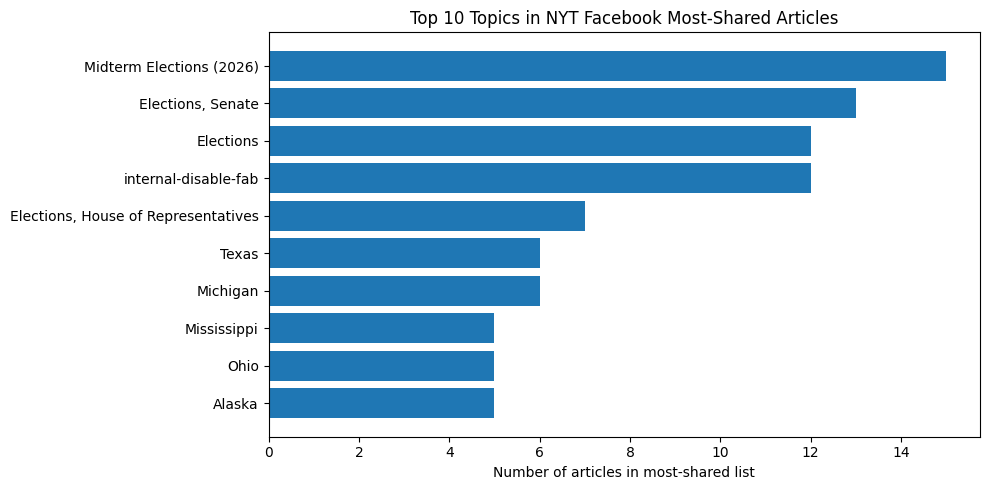

In [94]:
#Visualize the top 10 recurring topics

top10 = topic_counts.head(10)

plt.figure(figsize=(10, 5))

plt.barh(
    top10["topic"],
    top10["article_count"]
)

plt.xlabel("Number of articles in most-shared list")
plt.title("Top 10 Topics in NYT Facebook Most-Shared Articles")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [95]:
from datetime import datetime, timezone

snapshot = df.copy()

snapshot["snapshot_date"] = (
    datetime.now(timezone.utc).date().isoformat()
)

snapshot["facebook_rank"] = range(
    1, len(snapshot) + 1
)

snapshot.to_csv(
    f"facebook_{snapshot['snapshot_date'].iloc[0]}.csv",
    index=False
)

In [101]:
df = pd.DataFrame(data["results"])

# Preserve the popularity order returned by the API
df["facebook_rank"] = range(1, len(df) + 1)

print("Total articles:", len(df))
print("Available columns:", df.columns.tolist())

# Show every row and column in the notebook
with pd.option_context(
    "display.max_rows", None,
    "display.max_columns", None,
    "display.max_colwidth", 120
):
    display(df)
articles = df[[
    "facebook_rank",
    "title",
    "section",
    "published_date",
    "updated",
    "adx_keywords",
    "url"
]].copy()

articles["published_date"] = pd.to_datetime(
    articles["published_date"], utc=True
)

articles["updated"] = pd.to_datetime(
    articles["updated"], utc=True
)

articles["days_since_publication"] = (
    pd.Timestamp.now(tz="UTC") -
    articles["published_date"]
).dt.days

display(articles)

Total articles: 20
Available columns: ['uri', 'url', 'id', 'asset_id', 'source', 'published_date', 'updated', 'section', 'subsection', 'nytdsection', 'adx_keywords', 'column', 'byline', 'type', 'title', 'abstract', 'des_facet', 'org_facet', 'per_facet', 'geo_facet', 'media', 'eta_id', 'facebook_rank']


,uri,url,id,asset_id,source,published_date,updated,section,subsection,nytdsection,adx_keywords,column,byline,type,title,abstract,des_facet,org_facet,per_facet,geo_facet,media,eta_id,facebook_rank
0,nyt://article/e3d73fd3-63b2-5445-a63b-bafb94c1ba3c,https://www.nytimes.com/2026/10/30/business/obamacare-health-insurance-rates.html,100000011237835,100000011237835,New York Times,2026-10-30,2026-11-02 11:06:24,Business,,business,"Patient Protection and Affordable Care Act (2010);Health Insurance and Managed Care;Prices (Fares, Fees and Rates);U...",None,By Reed Abelson and Margot Sanger-Katz,Article,Obamacare Dealt Yet Another Blow as Premiums Jump Again,"Premiums will increase an average 13 percent next year for millions of Americans, on top of an earlier steep increas...","[Patient Protection and Affordable Care Act (2010), Health Insurance and Managed Care, Prices (Fares, Fees and Rates...",[],"[Trump, Donald J]",[United States],"[{'type': 'image', 'subtype': 'photo', 'caption': 'The average price of health insurance in the Obamacare marketplac...",0,1
1,nyt://article/8452b3d5-ac9c-51c4-bba7-0f1822f62ca3,https://www.nytimes.com/2026/11/02/business/economy/eeoc-trump-administration-pregnancy-fertility-abortion.html,100000011239652,100000011239652,New York Times,2026-11-02,2026-11-03 12:52:23,Business,Economy,business,United States Politics and Government;Law and Legislation;Pregnancy and Childbirth;Abortion;Women's Rights;Workplace...,None,By Coral Davenport and Rebecca Davis O’Brien,Article,Trump Administration Said to Plan Rolling Back Pregnancy-Related Job Protections,"The Biden era law was meant to help women stay in the workplace, but some conservatives say rules to enact it went t...","[United States Politics and Government, Law and Legislation, Pregnancy and Childbirth, Abortion, Women's Rights, Wor...",[Equal Employment Opportunity Commission],"[Lucas, Andrea R, Trump, Donald J]",[],"[{'type': 'image', 'subtype': 'photo', 'caption': 'A rally on Capitol Hill to support the Pregnant Workers Fairness ...",0,2
2,nyt://article/1907d15f-269d-5aee-991e-3daa245771af,https://www.nytimes.com/2026/11/04/us/politics/midterm-election-trump-voters.html,100000011259431,100000011259431,New York Times,2026-11-04,2026-11-04 22:08:42,U.S.,Politics,u.s.,"United States Politics and Government;Midterm Elections (2026);Polls and Public Opinion;Elections, House of Represen...",None,By Peter Baker,Article,Angry Voters Usher in Beginning of the End to the Trump Era,The electoral backlash extended even into deep red states and indicated that President Trump has lost his hold over ...,"[United States Politics and Government, Midterm Elections (2026), Polls and Public Opinion, Elections, House of Repr...","[Democratic Party, Republican Party]","[Trump, Donald J]",[],"[{'type': 'image', 'subtype': 'photo', 'caption': '“I wasn’t on the ticket, and because I wasn’t on the ticket, we c...",0,3
3,nyt://article/6c57e88b-c98c-5e99-919b-03173ec05df3,https://www.nytimes.com/2026/11/04/opinion/trump-democrats-midterms.html,100000011245120,100000011245120,New York Times,2026-11-04,2026-11-04 17:32:07,Opinion,,opinion,"United States Politics and Government;Midterm Elections (2026);Trump, Donald J;Democratic Party;House of Representat...",None,By Michelle Cottle,Article,Don’t Be Fooled. This Is What Trump Wanted.,The president loves combat and chaos. He’s about to get more of it.,"[United States Politics and Government, Midterm Elections (2026)]","[Democratic Party, House of Representatives, Republican Party, Senate]","[Trump, Donald J]",[United States],[],0,4
4,nyt://interactive/2f1644fa-4294-5fb2-8006-cffeb9119b5c,https://www.nytimes.com/interactive/2026/elections/voter-trends-national.html,100000011234831,100000011234831,New York Times,2026-11-04,2026-11-04 20:19:56,U.S.,Elections,u.s.,internal-disable-fab;Midterm Elections (2026),None,,Interactive,How Americans Voted in 2026,"Explore the results of the election by race, gender, age and education.","[internal-

,facebook_rank,title,section,published_date,updated,adx_keywords,url,days_since_publication
0,1,Obamacare Dealt Yet Another Blow as Premiums J...,Business,2026-10-30 00:00:00+00:00,2026-11-02 11:06:24+00:00,Patient Protection and Affordable Care Act (20...,https://www.nytimes.com/2026/10/30/business/ob...,6
1,2,Trump Administration Said to Plan Rolling Back...,Business,2026-11-02 00:00:00+00:00,2026-11-03 12:52:23+00:00,United States Politics and Government;Law and ...,https://www.nytimes.com/2026/11/02/business/ec...,3
2,3,Angry Voters Usher in Beginning of the End to ...,U.S.,2026-11-04 00:00:00+00:00,2026-11-04 22:08:42+00:00,United States Politics and Government;Midterm ...,https://www.nytimes.com/2026/11/04/us/politics...,1
3,4,Don’t Be Fooled. This Is What Trump Wanted.,Opinion,2026-11-04 00:00:00+00:00,2026-11-04 17:32:07+00:00,United States Politics and Government;Midterm ...,https://www.nytimes.com/2026/11/04/opinion/tru...,1
4,5,How Americans Voted in 2026,U.S.,2026-11-04 00:00:00+00:00,2026-11-04 20:19:56+00:00,internal-disable-fab;Midterm Elections (2026),https://www.nytimes.com/interactive/2026/elect...,1
5,6,"Patrick Stewart, Master of Shakespeare, ‘Star ...",Arts,2026-10-29 00:00:00+00:00,2026-10-30 20:46:33+00:00,Deaths (Obituaries);Theater;Television;Movies;...,https://www.nytimes.com/2026/10/29/arts/televi...,7
6,7,"Threats, Gaffes and Men’s Posteriors: Trump’s ...",U.S.,2026-11-01 00:00:00+00:00,2026-11-02 15:31:09+00:00,"Speeches and Statements;Age, Chronological;Ind...",https://www.nytimes.com/2026/11/01/us/politics...,4
7,8,The Brain Injury That Made a Middle School Tea...,Magazine,2026-11-02 00:00:00+00:00,2026-11-04 13:14:02+00:00,Music;Brain;Creativity;Traffic Accidents and S...,https://www.nytimes.com/interactive/2026/11/02...,3
8,9,Trump Says in Interview That He Will Accept El...,U.S.,2026-11-03 00:00:00+00:00,2026-11-04 09:42:01+00:00,"Elections, Senate;Elections, House of Represen...",https://www.nytimes.com/2026/11/03/us/politics...,2
9,10,Trump Delivers a Closing Midterm Message. Most...,U.S.,2026-11-02 00:00:00+00:00,2026-11-03 12:32:42+00:00,internal-open-access-from-nl;United States Pol...,https://www.nytimes.com/2026/11/02/us/politics...,3


In [102]:
topic_df = (
    articles.assign(
        topic=articles["adx_keywords"].fillna("").str.split(";")
    )
    .explode("topic")
)

topic_df["topic"] = topic_df["topic"].str.strip()
topic_df = topic_df[topic_df["topic"] != ""]

topic_summary = (
    topic_df.groupby("topic")
    .agg(
        article_count=("title", "count"),
        average_rank=("facebook_rank", "mean")
    )
    .sort_values(
        ["article_count", "average_rank"],
        ascending=[False, True]
    )
    .reset_index()
)

display(topic_summary.head(30))

,topic,article_count,average_rank
0,"Trump, Donald J",12,9.333333
1,Midterm Elections (2026),12,9.916667
2,United States Politics and Government,11,8.000000
3,Republican Party,7,10.571429
4,Democratic Party,6,9.000000
5,Polls and Public Opinion,4,9.500000
6,"Elections, Senate",4,9.750000
7,"Elections, House of Representatives",3,8.000000
8,United States,3,8.000000
9,internal-open-access-from-nl,3,10.000000


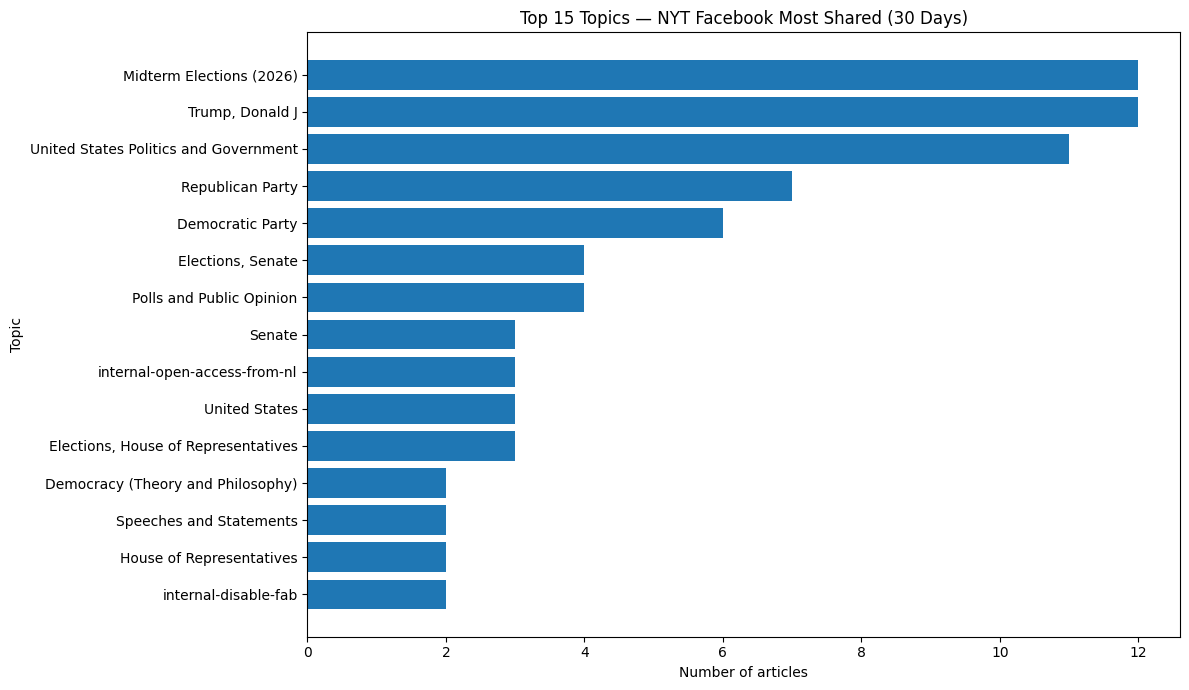

In [103]:
top15 = topic_summary.head(15).sort_values("article_count")

plt.figure(figsize=(12, 7))

plt.barh(
    top15["topic"],
    top15["article_count"]
)

plt.xlabel("Number of articles")
plt.ylabel("Topic")
plt.title("Top 15 Topics — NYT Facebook Most Shared (30 Days)")
plt.tight_layout()
plt.show()

,section,article_count,average_rank
0,U.S.,9,11.777778
1,Opinion,5,11.200000
2,Business,2,1.500000
3,Arts,1,6.000000
4,Magazine,1,8.000000
5,Technology,1,17.000000
6,World,1,14.000000


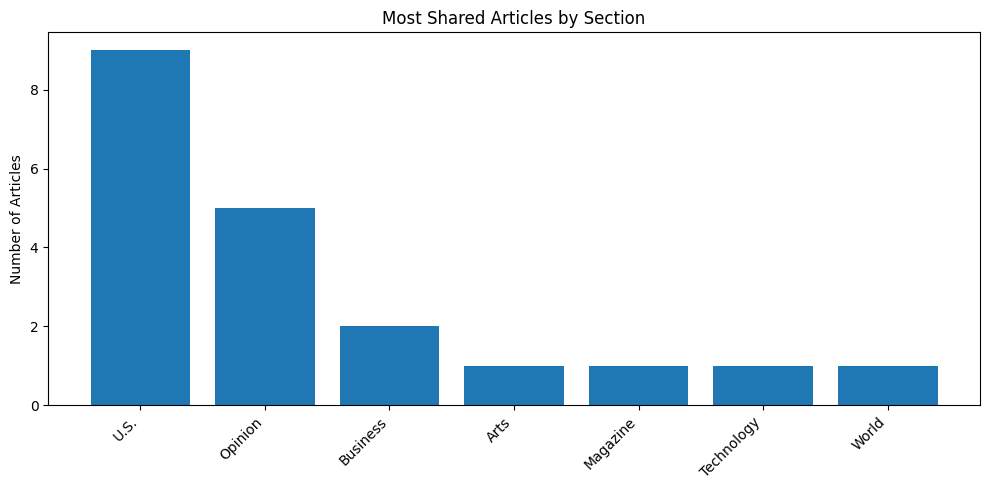

In [104]:
section_summary = (
    articles.groupby("section")
    .agg(
        article_count=("title", "count"),
        average_rank=("facebook_rank", "mean")
    )
    .sort_values("article_count", ascending=False)
    .reset_index()
)

display(section_summary)

plt.figure(figsize=(10, 5))
plt.bar(
    section_summary["section"],
    section_summary["article_count"]
)

plt.xticks(rotation=45, ha="right")
plt.title("Most Shared Articles by Section")
plt.ylabel("Number of Articles")
plt.tight_layout()
plt.show()

In [106]:
#Compare recent 14-day articles with the 30-day list
 
cutoff = pd.Timestamp.now(tz="UTC") - pd.Timedelta(days=14)

recent_14 = articles[
    articles["published_date"] >= cutoff
].copy()

print("Articles published within last 14 days:", len(recent_14))

display(recent_14)

Articles published within last 14 days: 20


,facebook_rank,title,section,published_date,updated,adx_keywords,url,days_since_publication
0,1,Obamacare Dealt Yet Another Blow as Premiums J...,Business,2026-10-30 00:00:00+00:00,2026-11-02 11:06:24+00:00,Patient Protection and Affordable Care Act (20...,https://www.nytimes.com/2026/10/30/business/ob...,6
1,2,Trump Administration Said to Plan Rolling Back...,Business,2026-11-02 00:00:00+00:00,2026-11-03 12:52:23+00:00,United States Politics and Government;Law and ...,https://www.nytimes.com/2026/11/02/business/ec...,3
2,3,Angry Voters Usher in Beginning of the End to ...,U.S.,2026-11-04 00:00:00+00:00,2026-11-04 22:08:42+00:00,United States Politics and Government;Midterm ...,https://www.nytimes.com/2026/11/04/us/politics...,1
3,4,Don’t Be Fooled. This Is What Trump Wanted.,Opinion,2026-11-04 00:00:00+00:00,2026-11-04 17:32:07+00:00,United States Politics and Government;Midterm ...,https://www.nytimes.com/2026/11/04/opinion/tru...,1
4,5,How Americans Voted in 2026,U.S.,2026-11-04 00:00:00+00:00,2026-11-04 20:19:56+00:00,internal-disable-fab;Midterm Elections (2026),https://www.nytimes.com/interactive/2026/elect...,1
5,6,"Patrick Stewart, Master of Shakespeare, ‘Star ...",Arts,2026-10-29 00:00:00+00:00,2026-10-30 20:46:33+00:00,Deaths (Obituaries);Theater;Television;Movies;...,https://www.nytimes.com/2026/10/29/arts/televi...,7
6,7,"Threats, Gaffes and Men’s Posteriors: Trump’s ...",U.S.,2026-11-01 00:00:00+00:00,2026-11-02 15:31:09+00:00,"Speeches and Statements;Age, Chronological;Ind...",https://www.nytimes.com/2026/11/01/us/politics...,4
7,8,The Brain Injury That Made a Middle School Tea...,Magazine,2026-11-02 00:00:00+00:00,2026-11-04 13:14:02+00:00,Music;Brain;Creativity;Traffic Accidents and S...,https://www.nytimes.com/interactive/2026/11/02...,3
8,9,Trump Says in Interview That He Will Accept El...,U.S.,2026-11-03 00:00:00+00:00,2026-11-04 09:42:01+00:00,"Elections, Senate;Elections, House of Represen...",https://www.nytimes.com/2026/11/03/us/politics...,2
9,10,Trump Delivers a Closing Midterm Message. Most...,U.S.,2026-11-02 00:00:00+00:00,2026-11-03 12:32:42+00:00,internal-open-access-from-nl;United States Pol...,https://www.nytimes.com/2026/11/02/us/politics...,3


In [107]:
#Compare topics: Recent 14 days vs. all 30 days
def count_topics(data):
    return (
        data["adx_keywords"]
        .fillna("")
        .str.split(";")
        .explode()
        .str.strip()
        .loc[lambda s: s.ne("")]
        .value_counts()
    )

topics_30 = count_topics(articles)
topics_14 = count_topics(recent_14)

comparison = pd.concat(
    [
        topics_30.rename("articles_30d_list"),
        topics_14.rename("articles_published_last_14d")
    ],
    axis=1
).fillna(0).astype(int)

comparison["recent_article_share"] = (
    comparison["articles_published_last_14d"] /
    comparison["articles_30d_list"]
).round(2)

comparison = comparison.sort_values(
    ["articles_published_last_14d", "articles_30d_list"],
    ascending=False
)

display(comparison.head(30))

,articles_30d_list,articles_published_last_14d,recent_article_share
"Trump, Donald J",12,12,1.0
Midterm Elections (2026),12,12,1.0
United States Politics and Government,11,11,1.0
Republican Party,7,7,1.0
Democratic Party,6,6,1.0
Polls and Public Opinion,4,4,1.0
"Elections, Senate",4,4,1.0
United States,3,3,1.0
Senate,3,3,1.0
internal-open-access-from-nl,3,3,1.0


In [108]:
pm_insights = topic_summary.head(10).copy()

pm_insights["potential_action"] = (
    "Investigate topic for editorial discovery and distribution"
)

display(pm_insights)

,topic,article_count,average_rank,potential_action
0,"Trump, Donald J",12,9.333333,Investigate topic for editorial discovery and ...
1,Midterm Elections (2026),12,9.916667,Investigate topic for editorial discovery and ...
2,United States Politics and Government,11,8.000000,Investigate topic for editorial discovery and ...
3,Republican Party,7,10.571429,Investigate topic for editorial discovery and ...
4,Democratic Party,6,9.000000,Investigate topic for editorial discovery and ...
5,Polls and Public Opinion,4,9.500000,Investigate topic for editorial discovery and ...
6,"Elections, Senate",4,9.750000,Investigate topic for editorial discovery and ...
7,"Elections, House of Representatives",3,8.000000,Investigate topic for editorial discovery and ...
8,United States,3,8.000000,Investigate topic for editorial discovery and ...
9,internal-open-access-from-nl,3,10.000000,Investigate topic for editorial discovery and ...
